<a href="https://colab.research.google.com/github/williamryanmckee-nwa/Deep-Learning/blob/main/MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Step-by-Step Autoencoder with the Actual MNIST Dataset

## Learning objectives
By the end of this notebook, you will be able to:

1. Load the real MNIST handwritten-digit dataset.
2. inspect its shape, labels, and pixel values.
3. Visualize original images.
4. Prepare images for a neural network.
5. Build an encoder–decoder autoencoder.
6. Train it to reconstruct its own input.
7. Compare original and reconstructed digits.
8. Inspect the compressed latent representation.
9. Measure reconstruction error and discuss practical uses.

**Key idea:** an autoencoder is trained with the image as both the input and the target. It learns to reconstruct the input rather than predict a digit label.

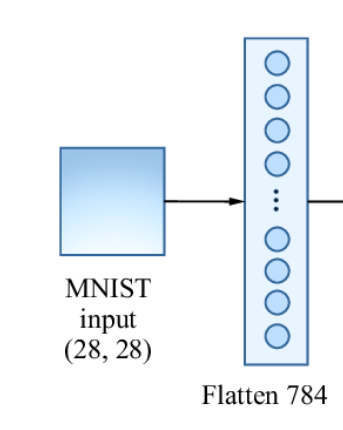

In [3]:
from IPython.display import Image

# Display a local image
Image(filename='MNIST Autoencoder Step-by-Step Infographic.png')


## 1. Import the required libraries

- **TensorFlow/Keras** builds and trains the neural network.
- **NumPy** helps inspect and reshape arrays.
- **Matplotlib** displays images and training curves.
- **Pandas** creates readable summaries.

In [4]:
!pip install tensorflow

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, Model

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

TensorFlow version: 2.21.0
NumPy version: 2.1.3


## 2. Load the actual MNIST dataset

MNIST contains 70,000 grayscale images of handwritten digits from 0 to 9. Each image is 28 × 28 pixels.

Keras splits the dataset into:
- 60,000 training images
- 10,000 test images

The labels are included in the dataset, but **the autoencoder does not need them for training**. We will keep the labels only to help us understand and display the digits.

In [6]:
(x_train_raw, y_train), (x_test_raw, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

print("Training images:", x_train_raw.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test_raw.shape)
print("Test labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


### What do these shapes mean?

- `x_train_raw.shape` should be `(60000, 28, 28)`: 60,000 images, each 28 rows by 28 columns.
- `y_train.shape` should be `(60000,)`: one digit label for each training image.
- Pixel values are grayscale intensities, normally integers from **0 to 255**.

In [7]:
print("Data type:", x_train_raw.dtype)
print("Minimum pixel value:", x_train_raw.min())
print("Maximum pixel value:", x_train_raw.max())
print("First 20 training labels:", y_train[:20])

summary = pd.DataFrame({
    "Property": ["Training images", "Test images", "Image height", "Image width",
                 "Pixel minimum", "Pixel maximum", "Number of classes"],
    "Value": [len(x_train_raw), len(x_test_raw), x_train_raw.shape[1],
              x_train_raw.shape[2], int(x_train_raw.min()),
              int(x_train_raw.max()), len(np.unique(y_train))]
})
summary

Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
First 20 training labels: [5 0 4 1 9 2 1 3 1 4 3 5 3 6 1 7 2 8 6 9]


,Property,Value
0,Training images,60000
1,Test images,10000
2,Image height,28
3,Image width,28
4,Pixel minimum,0
5,Pixel maximum,255
6,Number of classes,10


## 3. Visualize real MNIST images

Each image is a grid of 784 pixel values. `imshow` displays the 28 × 28 grid as a picture.

The label shown above each image is the known digit supplied by MNIST. The autoencoder will not use this label as its training target.

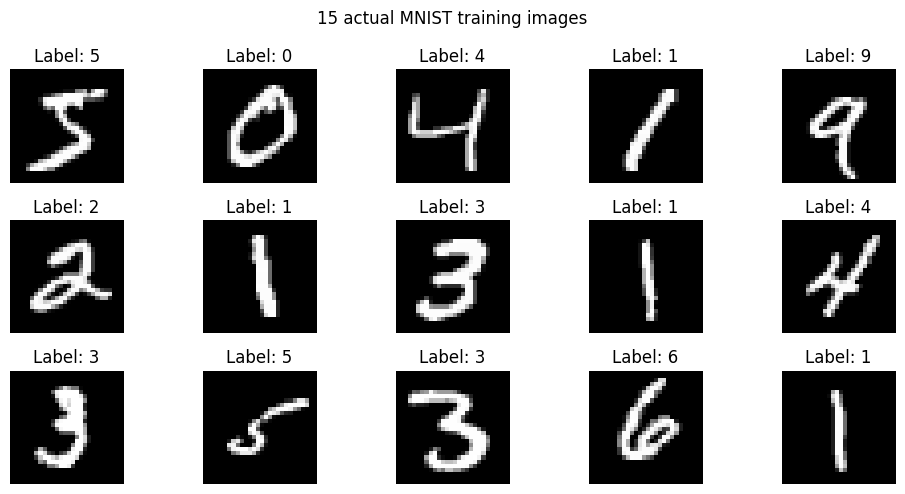

In [8]:
plt.figure(figsize=(10, 5))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_train_raw[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.suptitle("15 actual MNIST training images")
plt.tight_layout()
plt.show()

## 4. Inspect one image as a numeric matrix

An image is not stored as a word or digit. It is stored as numbers. Each number represents the brightness of one pixel.

- `0` means black.
- `255` means white.
- Values between 0 and 255 represent shades of gray.

Let's inspect the first image as both a picture and a small numeric matrix.

Label for this image: 5
Image shape: (28, 28)
First 10 rows and columns of pixel values:
[[  0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36]
 [  0   0   0   0   0   0   0  49 238 253]
 [  0   0   0   0   0   0   0  18 219 253]
 [  0   0   0   0   0   0   0   0  80 156]]


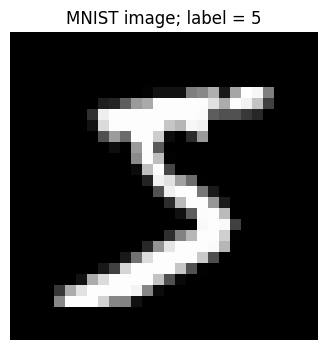

In [9]:
image_index = 0
one_image = x_train_raw[image_index]

print("Label for this image:", y_train[image_index])
print("Image shape:", one_image.shape)
print("First 10 rows and columns of pixel values:")
print(one_image[:10, :10])

plt.figure(figsize=(4, 4))
plt.imshow(one_image, cmap="gray")
plt.title(f"MNIST image; label = {y_train[image_index]}")
plt.axis("off")
plt.show()

## 5. Normalize pixel values

Neural networks generally train more smoothly when inputs are on a small scale. We divide every pixel by 255, converting values from `[0, 255]` to `[0, 1]`.

We use `float32` so the values are suitable for TensorFlow training.

In [10]:
x_train = x_train_raw.astype("float32") / 255.0
x_test = x_test_raw.astype("float32") / 255.0

print("Before normalization:", x_train_raw.min(), "to", x_train_raw.max())
print("After normalization:", x_train.min(), "to", x_train.max())
print("Normalized data type:", x_train.dtype)

Before normalization: 0 to 255
After normalization: 0.0 to 1.0
Normalized data type: float32


### Compare pixels before and after normalization

The image should look the same to a person, even though the numeric values have changed.

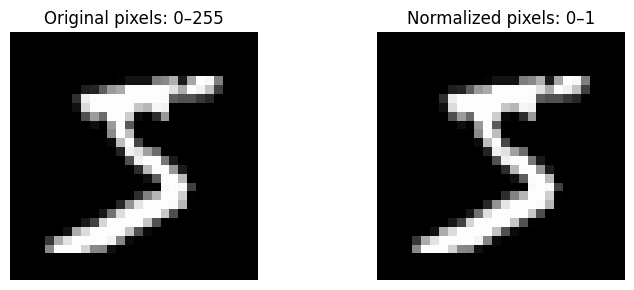

In [11]:
plt.figure(figsize=(8, 3))

plt.subplot(1, 2, 1)
plt.imshow(x_train_raw[image_index], cmap="gray", vmin=0, vmax=255)
plt.title("Original pixels: 0–255")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(x_train[image_index], cmap="gray", vmin=0, vmax=1)
plt.title("Normalized pixels: 0–1")
plt.axis("off")

plt.tight_layout()
plt.show()

## 6. Flatten each image from 2D to 1D

The original image shape is `(28, 28)`. A fully connected (`Dense`) layer expects a vector per example, so we reshape each image into 784 values.

This changes the array shape but does **not** change the pixel values. Later, the decoder will output 784 values again.

In [12]:
x_train_flat = x_train.reshape(-1, 28 * 28)
x_test_flat = x_test.reshape(-1, 28 * 28)

print("Before flattening:", x_train.shape)
print("After flattening:", x_train_flat.shape)
print("Test data after flattening:", x_test_flat.shape)
print("Number of pixels per image:", x_train_flat.shape[1])

Before flattening: (60000, 28, 28)
After flattening: (60000, 784)
Test data after flattening: (10000, 784)
Number of pixels per image: 784


### Verify flattening is reversible

We can reshape the first 784 values back into a 28 × 28 image. It should match the normalized original exactly, apart from no expected numerical change from this reshape operation.

Same pixel values after reshape: True


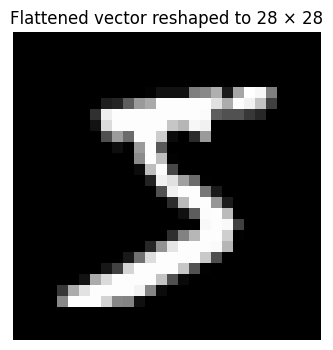

In [13]:
restored_shape = x_train_flat[image_index].reshape(28, 28)

print("Same pixel values after reshape:",
      np.array_equal(restored_shape, x_train[image_index]))

plt.figure(figsize=(4, 4))
plt.imshow(restored_shape, cmap="gray", vmin=0, vmax=1)
plt.title("Flattened vector reshaped to 28 × 28")
plt.axis("off")
plt.show()

## 7. Design the autoencoder

Our network has these layers:

| Part | Layer | Purpose |
|---|---|---|
| Input | 784 values | One flattened MNIST image |
| Encoder | Dense(128, ReLU) | Learn intermediate features |
| Bottleneck | Dense(32, ReLU) | Compress 784 values to 32 features |
| Decoder | Dense(128, ReLU) | Rebuild features from the compact code |
| Output | Dense(784, sigmoid) | Reconstruct normalized pixel values |

The bottleneck contains 32 values instead of 784, a reduction in representation size of 24.5 times (`784 / 32`).

The sigmoid output activation is appropriate here because our target pixels are normalized to the range `[0, 1]`.

In [14]:
# Encoder
inputs = layers.Input(shape=(784,), name="image_pixels")
x = layers.Dense(128, activation="relu", name="encoder_hidden")(inputs)
latent = layers.Dense(32, activation="relu", name="latent_representation")(x)

# Decoder
x = layers.Dense(128, activation="relu", name="decoder_hidden")(latent)
outputs = layers.Dense(784, activation="sigmoid", name="reconstructed_pixels")(x)

autoencoder = Model(inputs=inputs, outputs=outputs, name="mnist_autoencoder")

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

autoencoder.summary()

Model: "mnist_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_pixels (InputLayer)       │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_hidden (Dense)          │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_representation (Dense)   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_hidden (Dense)          │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstructed_pixels (Dense)    │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

## 8. Create a separate encoder model

The complete autoencoder returns a reconstructed image. The encoder model returns only the 32-value compressed representation.

This lets us inspect the latent vector directly.

In [15]:
encoder = Model(inputs=inputs, outputs=latent, name="mnist_encoder")

print("Input shape:", encoder.input_shape)
print("Compressed representation shape:", encoder.output_shape)

Input shape: (None, 784)
Compressed representation shape: (None, 32)


## 9. Train the autoencoder

**Important:** `x_train_flat` appears twice:
- As the input: the image the model receives.
- As the target: the image the model should reconstruct.

We are not training it to predict `y_train`. The digit labels are not passed into `fit`.

The test images are used for validation during training. Five epochs is a reasonable short demonstration; increasing the epoch count may improve reconstruction but takes longer.

In [16]:
history = autoencoder.fit(
    x_train_flat,
    x_train_flat,
    epochs=5,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test_flat, x_test_flat),
    verbose=1
)

Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 0.0598 - val_loss: 0.0330
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - loss: 0.0264 - val_loss: 0.0214
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0195 - val_loss: 0.0171
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0164 - val_loss: 0.0151
Epoch 5/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0148 - val_loss: 0.0139


### What does the loss mean?

We use mean squared error (MSE). For each pixel, it calculates the squared difference between the original value and reconstructed value, then averages the differences.

- Lower loss means the reconstruction is closer to the target on average.
- Training loss is measured on training images.
- Validation loss is measured on test images held aside from weight updates.

A low reconstruction loss does not automatically mean that the compressed representation is useful for every downstream task.

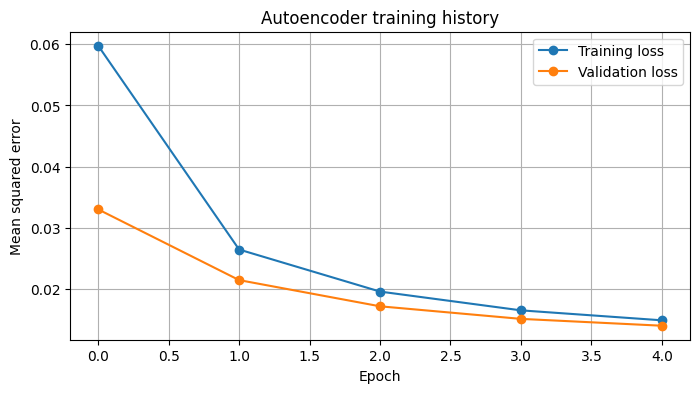

Final training loss: 0.014818521216511726
Final validation loss: 0.013932238332927227


In [17]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], marker="o", label="Training loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("Autoencoder training history")
plt.legend()
plt.grid(True)
plt.show()

print("Final training loss:", history.history["loss"][-1])
print("Final validation loss:", history.history["val_loss"][-1])

## 10. Reconstruct unseen test images

We now give the model test images it did not use to update its weights. It produces a reconstruction for each image.

In [18]:
reconstructed = autoencoder.predict(x_test_flat[:10], verbose=0)

print("Input batch shape:", x_test_flat[:10].shape)
print("Reconstructed batch shape:", reconstructed.shape)
print("Output values range:",
      float(reconstructed.min()), "to", float(reconstructed.max()))

Input batch shape: (10, 784)
Reconstructed batch shape: (10, 784)
Output values range: 2.265748569665882e-12 to 0.999176025390625


### Display original and reconstructed digits

The top row shows original test images. The bottom row shows the model's reconstructions. Reconstructions may be blurrier or lose small details because the bottleneck has limited capacity.

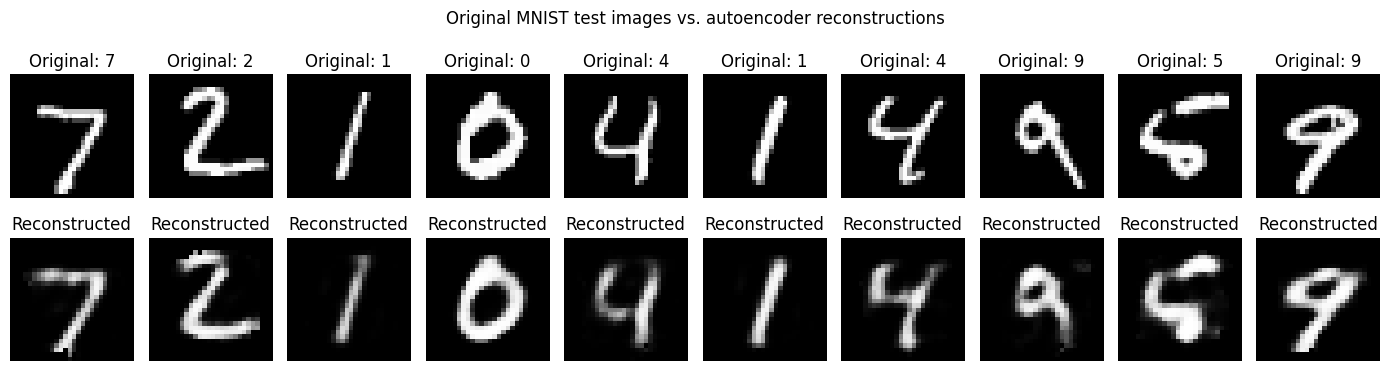

In [19]:
n = 10
plt.figure(figsize=(14, 4))

for i in range(n):
    # Original image
    plt.subplot(2, n, i + 1)
    plt.imshow(x_test_flat[i].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    plt.title(f"Original: {y_test[i]}")
    plt.axis("off")

    # Reconstructed image
    plt.subplot(2, n, n + i + 1)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    plt.title("Reconstructed")
    plt.axis("off")

plt.suptitle("Original MNIST test images vs. autoencoder reconstructions")
plt.tight_layout()
plt.show()

## 11. Inspect the latent representation

The encoder transforms each 784-value test image into 32 learned values. These values are not the digit label; they are features learned to help the decoder reconstruct the image.

In [20]:
latent_vectors = encoder.predict(x_test_flat[:10], verbose=0)

print("Latent vectors shape:", latent_vectors.shape)
print("First image's 32-value latent vector:")
print(np.round(latent_vectors[0], 3))

Latent vectors shape: (10, 32)
First image's 32-value latent vector:
[ 0.    10.344  9.099  3.559  4.964  2.876  2.063  0.     8.445  3.479
  9.6    0.     6.825  7.92   8.714  0.     7.82   5.994 10.372  5.34
 13.062 11.062  2.915  5.767  5.289  7.955 15.756 13.694  4.262  0.
  5.905 10.128]


## 12. Calculate reconstruction error

For each test image, we calculate its average squared pixel difference from its reconstruction. This provides a numerical measure of reconstruction quality.

In [21]:
squared_errors = (x_test_flat[:len(reconstructed)] - reconstructed) ** 2
per_image_mse = np.mean(squared_errors, axis=1)

error_table = pd.DataFrame({
    "Test image index": np.arange(len(per_image_mse)),
    "True digit label (not used for training)": y_test[:len(per_image_mse)],
    "Reconstruction MSE": per_image_mse
})
error_table

,Test image index,True digit label (not used for training),Reconstruction MSE
0,0,7,0.010200
1,1,2,0.014660
2,2,1,0.003890
3,3,0,0.008401
4,4,4,0.012941
5,5,1,0.001614
6,6,4,0.016239
7,7,9,0.018197
8,8,5,0.023502
9,9,9,0.014241


### View the image with the largest error in this batch

This only finds the highest error among the ten test images reconstructed above, not across the entire test set.

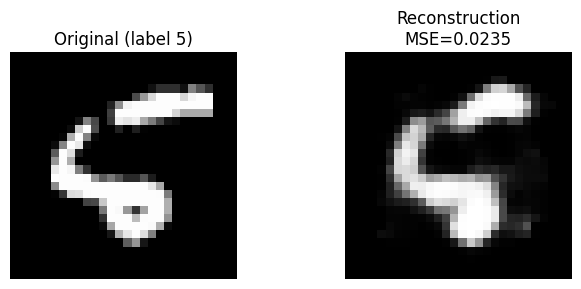

In [22]:
worst_idx = int(np.argmax(per_image_mse))

plt.figure(figsize=(7, 3))

plt.subplot(1, 2, 1)
plt.imshow(x_test_flat[worst_idx].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
plt.title(f"Original (label {y_test[worst_idx]})")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(reconstructed[worst_idx].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
plt.title(f"Reconstruction\nMSE={per_image_mse[worst_idx]:.4f}")
plt.axis("off")

plt.tight_layout()
plt.show()

## 13. Optional: reconstruct the full test set

This cell runs inference on all 10,000 test images and summarizes reconstruction errors. It is optional because it requires additional computation.

In [23]:
all_reconstructed = autoencoder.predict(x_test_flat, batch_size=256, verbose=1)
all_test_mse = np.mean((x_test_flat - all_reconstructed) ** 2, axis=1)

print("Number of test images evaluated:", len(all_test_mse))
print("Mean test reconstruction MSE:", float(all_test_mse.mean()))
print("Median test reconstruction MSE:", float(np.median(all_test_mse)))
print("95th percentile test reconstruction MSE:",
      float(np.percentile(all_test_mse, 95)))

40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Number of test images evaluated: 10000
Mean test reconstruction MSE: 0.013932240195572376
Median test reconstruction MSE: 0.012992845848202705
95th percentile test reconstruction MSE: 0.027068693190813065


## 14. Summary: what we did to the actual MNIST data

1. **Loaded** 60,000 training images and 10,000 test images.
2. **Inspected** image dimensions, labels, data type, and pixel range.
3. **Visualized** actual handwritten digits.
4. **Normalized** pixel values from `[0, 255]` to `[0, 1]`.
5. **Flattened** each 28 × 28 image into a 784-value vector.
6. **Built** an encoder, 32-value bottleneck, and decoder.
7. **Trained** the network with each image as its own target.
8. **Reconstructed** held-out test images.
9. **Examined** the latent vectors and reconstruction errors.

### Practical applications
- **Denoising:** learn to recover cleaner images from noisy inputs.
- **Anomaly detection:** train mostly on normal examples and flag unusually high reconstruction error.
- **Dimensionality reduction:** use encoder outputs as compact features.
- **Compression experiments:** study how reconstruction quality changes as the bottleneck size changes.

**Important limitation:** this notebook demonstrates a basic fully connected autoencoder. It is educational, not a production image-compression system. A convolutional autoencoder often preserves spatial image structure more effectively.